# Practical Assignment 5: Ensemble Learning and Performance Evaluation

## Student Details
- **Name:** Dhruv Bompilwar
- **PRN:** 202401040200
- **Roll No.:** 49
- **Division:** A
- **Batch:** A2

## Aim
Implement and evaluate stacking, AdaBoost, and voting ensembles, and compare them with individual machine-learning classifiers using classification metrics.

## Dataset
This notebook uses `sdg3_health_raw(1).csv`, the uploaded SDG 3 health dataset. A four-class target, `infant_mortality_risk`, is created from infant mortality:
- Low: below 10 deaths per 1,000 live births
- Moderate: 10–30
- High: above 30 through 60
- Very high: above 60

**Leakage prevention:** `infant_mortality_per_1000` is used only to create the target and is then removed from the features. Rows with missing infant mortality are excluded. Preprocessing is fitted inside each model pipeline, after the train/test split. The data is split randomly with a fixed seed for reproducibility; for a time- or country-generalization study, a grouped or temporal split would be preferable.


In [1]:
# Imports
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, AdaBoostClassifier, StackingClassifier, VotingClassifier
)
from sklearn.svm import SVC

RANDOM_STATE = 42


## 1. Load and inspect the dataset

Upload the CSV to the same folder as this notebook, or update `DATA_PATH` below to its location. This notebook intentionally uses the raw dataset so engineered features that encode the target are not accidentally included.

In [3]:
DATA_PATH = "sdg3_health_raw(1).csv"
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())
display(df.info())
display(df.isna().sum().sort_values(ascending=False).head(10))


Dataset shape: (11935, 20)


,iso3,country,region,income_group,year,life_expectancy,infant_mortality_per_1000,birth_rate_per_1000,death_rate_per_1000,health_expenditure_pct_gdp,health_expenditure_per_capita_usd,physicians_per_1000,hospital_beds_per_1000,basic_sanitation_pct,basic_drinking_water_pct,population,gdp_per_capita_usd,urban_population_pct,unemployment_pct,measles_immunization_pct
0,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,1970,37.460,223.8,51.207,26.838,NaN,NaN,0.065,0.199,NaN,NaN,11290128.0,NaN,11.229766,NaN,NaN
1,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,1971,37.932,249.0,51.303,26.383,NaN,NaN,NaN,NaN,NaN,NaN,11567667.0,NaN,11.666036,NaN,NaN
2,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,1972,38.423,245.2,51.244,25.882,NaN,NaN,NaN,NaN,NaN,NaN,11853696.0,NaN,12.161985,NaN,NaN
3,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,1973,38.951,214.8,51.278,25.364,NaN,NaN,NaN,NaN,NaN,NaN,12157999.0,NaN,12.691692,NaN,NaN
4,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,1974,39.469,211.6,51.373,24.889,NaN,NaN,NaN,NaN,NaN,NaN,12469127.0,NaN,13.234771,NaN,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11935 entries, 0 to 11934
Data columns (total 20 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   iso3                               11935 non-null  object 
 1   country                            11935 non-null  object 
 2   region                             11935 non-null  object 
 3   income_group                       11935 non-null  object 
 4   year                               11935 non-null  int64  
 5   life_expectancy                    11915 non-null  float64
 6   infant_mortality_per_1000          10432 non-null  float64
 7   birth_rate_per_1000                11915 non-null  float64
 8   death_rate_per_1000                11915 non-null  float64
 9   health_expenditure_pct_gdp         4562 non-null   float64
 10  health_expenditure_per_capita_usd  4559 non-null   float64
 11  physicians_per_1000                4978 non-null   flo

None

,0
hospital_beds_per_1000,7376
health_expenditure_per_capita_usd,7376
health_expenditure_pct_gdp,7373
physicians_per_1000,6957
basic_sanitation_pct,6769
basic_drinking_water_pct,6726
unemployment_pct,5586
measles_immunization_pct,4004
gdp_per_capita_usd,1546
infant_mortality_per_1000,1503


## 2. Prepare the classification target and features

The target is derived from infant mortality thresholds. The numeric value used to construct the target is excluded from `X` to avoid target leakage.

In [4]:
required = {"infant_mortality_per_1000"}
missing_required = required - set(df.columns)
if missing_required:
    raise ValueError(f"Required columns missing from dataset: {missing_required}")

data = df.dropna(subset=["infant_mortality_per_1000"]).copy()

def assign_risk(value):
    if value < 10:
        return "Low (<10)"
    elif value <= 30:
        return "Moderate (10-30)"
    elif value <= 60:
        return "High (30-60)"
    return "Very high (>60)"

data["infant_mortality_risk"] = data["infant_mortality_per_1000"].apply(assign_risk)
y = data["infant_mortality_risk"]
X = data.drop(columns=["infant_mortality_per_1000", "infant_mortality_risk"])

# Remove identifier-like columns that may encourage memorization rather than generalizable learning.
X = X.drop(columns=[c for c in ["iso3", "country"] if c in X.columns])

print("Feature matrix:", X.shape)
print("\nTarget distribution:")
display(y.value_counts().rename_axis("class").to_frame("count"))
display((y.value_counts(normalize=True) * 100).round(2).rename("percent").to_frame())


Feature matrix: (10432, 17)

Target distribution:


,count
class,
Moderate (10-30),3184
Very high (>60),2800
High (30-60),2266
Low (<10),2182


,percent
infant_mortality_risk,
Moderate (10-30),30.52
Very high (>60),26.84
High (30-60),21.72
Low (<10),20.92


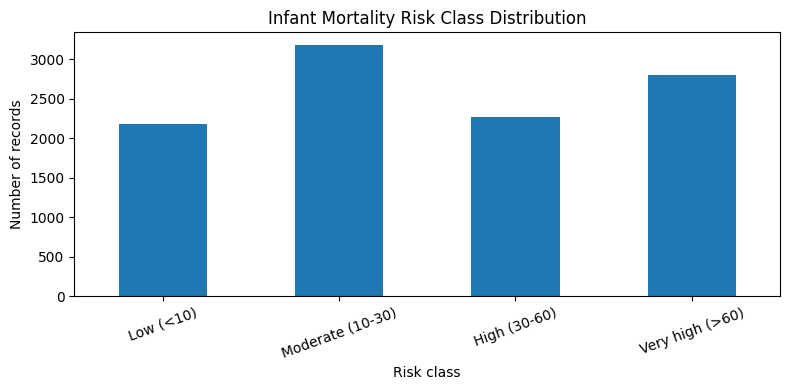

Training rows: 8345 | Test rows: 2087
Numeric features: 15 | Categorical features: 2


In [5]:
# Visualize class distribution
y.value_counts().reindex(["Low (<10)", "Moderate (10-30)", "High (30-60)", "Very high (>60)"]).plot(
    kind="bar", figsize=(8, 4), rot=20
)
plt.title("Infant Mortality Risk Class Distribution")
plt.xlabel("Risk class")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

# Train/test split: stratification preserves class proportions in both partitions.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

categorical_features = X_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
numeric_features = [c for c in X_train.columns if c not in categorical_features]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print(f"Training rows: {len(X_train)} | Test rows: {len(X_test)}")
print(f"Numeric features: {len(numeric_features)} | Categorical features: {len(categorical_features)}")


## 3. Define base classifiers

The same preprocessing and train/test split are used for each model to make the comparison fair. Logistic Regression and SVM provide linear/nonlinear baselines; Decision Tree and Random Forest provide tree-based baselines.

In [6]:
def make_pipeline(classifier):
    return Pipeline(steps=[
        ("preprocess", preprocessor),
        ("classifier", classifier)
    ])

base_models = {
    "Logistic Regression": make_pipeline(
        LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)
    ),
    "Decision Tree": make_pipeline(
        DecisionTreeClassifier(max_depth=8, class_weight="balanced", random_state=RANDOM_STATE)
    ),
    "Random Forest": make_pipeline(
        RandomForestClassifier(n_estimators=200, min_samples_leaf=2, class_weight="balanced",
                               n_jobs=-1, random_state=RANDOM_STATE)
    ),
    "SVM (RBF)": make_pipeline(
        SVC(kernel="rbf", C=1.0, probability=True, class_weight="balanced", random_state=RANDOM_STATE)
    )
}


## 4. Implement the ensemble models

- **Stacking:** base estimators generate out-of-fold predictions for a Logistic Regression meta-classifier.
- **AdaBoost:** combines weak Decision Tree stumps by increasing attention to previously misclassified examples.
- **Voting:** hard voting predicts the class with the most base-model votes (majority voting). Soft voting averages class probabilities and is also included for comparison.

The preprocessing is embedded in each base estimator. AdaBoost uses a shallow tree as its weak learner.

In [7]:
# Stacking ensemble
stacking = StackingClassifier(
    estimators=[
        ("lr", make_pipeline(LogisticRegression(max_iter=2000, class_weight="balanced"))),
        ("dt", make_pipeline(DecisionTreeClassifier(max_depth=6, class_weight="balanced",
                                                    random_state=RANDOM_STATE))),
        ("rf", make_pipeline(RandomForestClassifier(n_estimators=120, min_samples_leaf=2,
                                                    class_weight="balanced", n_jobs=-1,
                                                    random_state=RANDOM_STATE)))
    ],
    final_estimator=LogisticRegression(max_iter=2000, class_weight="balanced"),
    cv=5,
    stack_method="predict_proba",
    n_jobs=-1
)

# AdaBoost ensemble
# Compatibility with scikit-learn versions using either `estimator` or `base_estimator`.
weak_learner = make_pipeline(DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE))
try:
    adaboost = AdaBoostClassifier(estimator=weak_learner, n_estimators=100,
                                  learning_rate=0.5, random_state=RANDOM_STATE)
except TypeError:
    adaboost = AdaBoostClassifier(base_estimator=weak_learner, n_estimators=100,
                                  learning_rate=0.5, random_state=RANDOM_STATE)

# Hard majority voting
voting_hard = VotingClassifier(
    estimators=[
        ("lr", make_pipeline(LogisticRegression(max_iter=2000, class_weight="balanced"))),
        ("dt", make_pipeline(DecisionTreeClassifier(max_depth=6, class_weight="balanced",
                                                    random_state=RANDOM_STATE))),
        ("rf", make_pipeline(RandomForestClassifier(n_estimators=120, min_samples_leaf=2,
                                                    class_weight="balanced", n_jobs=-1,
                                                    random_state=RANDOM_STATE)))
    ],
    voting="hard",
    n_jobs=-1
)

# Soft voting averages class probabilities; included as an additional comparison.
voting_soft = VotingClassifier(
    estimators=[
        ("lr", make_pipeline(LogisticRegression(max_iter=2000, class_weight="balanced"))),
        ("dt", make_pipeline(DecisionTreeClassifier(max_depth=6, class_weight="balanced",
                                                    random_state=RANDOM_STATE))),
        ("rf", make_pipeline(RandomForestClassifier(n_estimators=120, min_samples_leaf=2,
                                                    class_weight="balanced", n_jobs=-1,
                                                    random_state=RANDOM_STATE)))
    ],
    voting="soft",
    n_jobs=-1
)

all_models = {**base_models, "Stacking": stacking, "AdaBoost": adaboost,
              "Voting (Hard)": voting_hard, "Voting (Soft)": voting_soft}
print("Models to evaluate:", ", ".join(all_models.keys()))


Models to evaluate: Logistic Regression, Decision Tree, Random Forest, SVM (RBF), Stacking, AdaBoost, Voting (Hard), Voting (Soft)


## 5. Train models and evaluate performance

Metrics reported:
- **Accuracy:** overall fraction of correct predictions.
- **Macro precision, recall and F1:** average across classes, giving each class equal weight.
- **Weighted F1:** class-wise F1 weighted by support.

Macro F1 is particularly useful when class frequencies differ. All reported results are measured on the held-out test set.

In [9]:
results = []
fitted_models = {}
predictions = {}

# Re-wrap AdaBoost if it was configured with a pipeline as its internal weak learner
# to prevent validation errors on missing data during fitting.
if "AdaBoost" in all_models:
    model_obj = all_models["AdaBoost"]
    if isinstance(model_obj, AdaBoostClassifier):
        # Extract the estimator (which is a pipeline with preprocessing)
        try:
            internal_est = model_obj.estimator
        except AttributeError:
            internal_est = model_obj.base_estimator

        if isinstance(internal_est, Pipeline):
            # Reconstruct AdaBoost as a standard pipeline wrapper
            plain_dt = DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE)
            try:
                new_adaboost = AdaBoostClassifier(estimator=plain_dt, n_estimators=100,
                                              learning_rate=0.5, random_state=RANDOM_STATE)
            except TypeError:
                new_adaboost = AdaBoostClassifier(base_estimator=plain_dt, n_estimators=100,
                                              learning_rate=0.5, random_state=RANDOM_STATE)
            all_models["AdaBoost"] = make_pipeline(new_adaboost)

for name, model in all_models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    fitted_models[name] = model
    predictions[name] = y_pred
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro Precision": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "Weighted F1": f1_score(y_test, y_pred, average="weighted", zero_division=0)
    })

results_df = pd.DataFrame(results).sort_values("Macro F1", ascending=False).reset_index(drop=True)
display(results_df.round(4))

Training Logistic Regression...
Training Decision Tree...
Training Random Forest...
Training SVM (RBF)...
Training Stacking...
Training AdaBoost...
Training Voting (Hard)...
Training Voting (Soft)...


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,Stacking,0.9583,0.9576,0.9582,0.9579,0.9582
1,Random Forest,0.9535,0.9539,0.9524,0.9531,0.9535
2,Voting (Hard),0.9023,0.9027,0.9001,0.9013,0.9025
3,Voting (Soft),0.9008,0.9012,0.8986,0.8998,0.9009
4,SVM (RBF),0.8951,0.8946,0.8943,0.8943,0.8955
5,Decision Tree,0.8807,0.8809,0.8818,0.8809,0.8816
6,Logistic Regression,0.8491,0.8478,0.8503,0.8487,0.8499
7,AdaBoost,0.7815,0.7844,0.7815,0.7820,0.7835


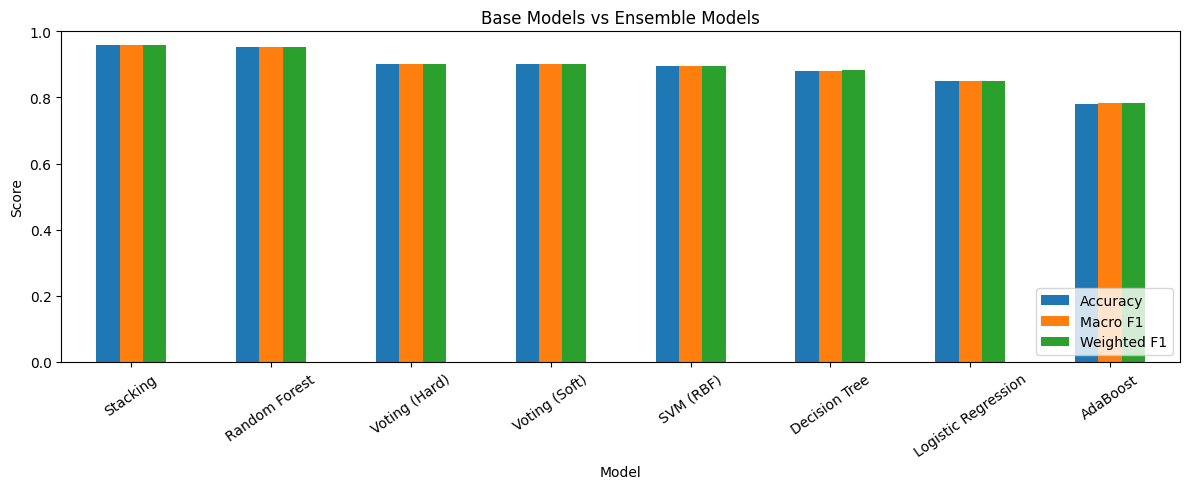

Best model by test Macro F1: Stacking
Best Macro F1: 0.9579


In [10]:
# Compare model metrics visually
plot_df = results_df.set_index("Model")[["Accuracy", "Macro F1", "Weighted F1"]]
ax = plot_df.plot(kind="bar", figsize=(12, 5), rot=35)
ax.set_title("Base Models vs Ensemble Models")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

print("Best model by test Macro F1:", results_df.iloc[0]["Model"])
print("Best Macro F1:", round(results_df.iloc[0]["Macro F1"], 4))


## 6. Detailed classification reports and confusion matrices

The classification report gives precision, recall, F1-score and support for each risk class. Confusion matrices help identify which risk levels are most often confused.


Logistic Regression
                  precision    recall  f1-score   support

    High (30-60)       0.72      0.77      0.74       453
       Low (<10)       0.91      0.93      0.92       437
Moderate (10-30)       0.86      0.83      0.84       637
 Very high (>60)       0.91      0.88      0.89       560

        accuracy                           0.85      2087
       macro avg       0.85      0.85      0.85      2087
    weighted avg       0.85      0.85      0.85      2087


Decision Tree
                  precision    recall  f1-score   support

    High (30-60)       0.77      0.84      0.80       453
       Low (<10)       0.94      0.92      0.93       437
Moderate (10-30)       0.88      0.86      0.87       637
 Very high (>60)       0.93      0.91      0.92       560

        accuracy                           0.88      2087
       macro avg       0.88      0.88      0.88      2087
    weighted avg       0.88      0.88      0.88      2087


Random Forest
               

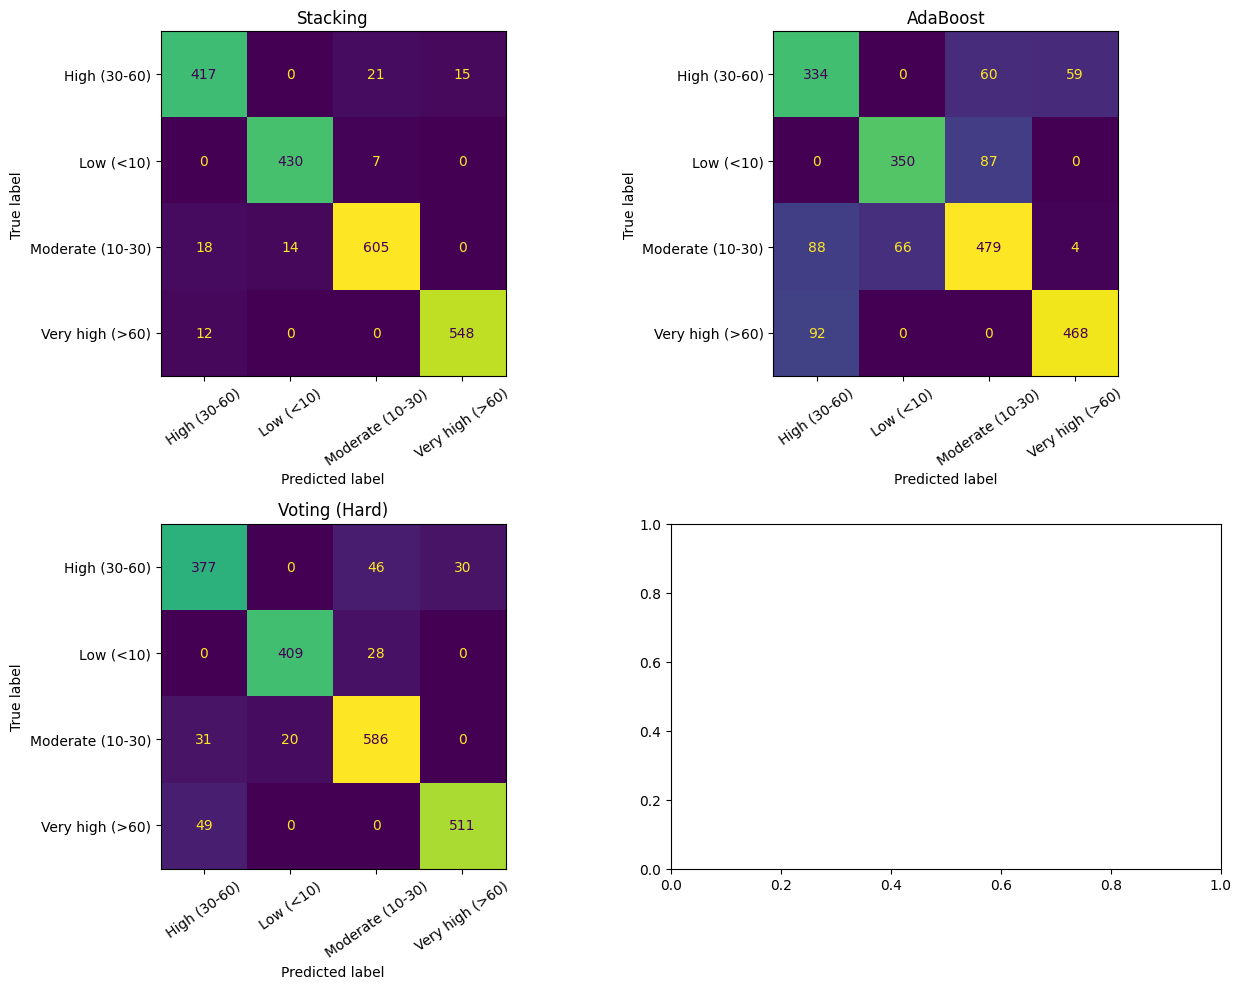

In [11]:
for name, y_pred in predictions.items():
    print("\n" + "=" * 80)
    print(name)
    print(classification_report(y_test, y_pred, zero_division=0))

# Show confusion matrices for the best model and the three ensemble methods.
selected = list(dict.fromkeys([
    results_df.iloc[0]["Model"], "Stacking", "AdaBoost", "Voting (Hard)"
]))
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for ax, name in zip(axes.ravel(), selected):
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions[name], ax=ax, xticks_rotation=35, colorbar=False
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()


## 7. Findings and interpretation

The table and plots above are generated from the actual held-out test predictions, so use those results to state which model performed best. Avoid assuming an ensemble must outperform every base model: ensemble performance depends on the diversity and quality of its component learners.

### When to use each method
- **Stacking:** useful when base learners make complementary errors and a meta-classifier can learn how to combine them. It is more computationally expensive and needs careful cross-validation.
- **AdaBoost:** useful when relatively simple weak learners can improve sequentially by focusing on difficult cases. It can be sensitive to noisy labels and outliers.
- **Hard voting:** useful when a simple, interpretable majority decision across several reasonably strong models is desired. It does not use confidence scores.
- **Soft voting:** useful when models provide meaningful, reasonably calibrated class probabilities; a model with overconfident probabilities can hurt the result.
- **Single models:** may be preferable when speed, ease of deployment, or interpretability matters, or when the ensemble gives little measurable improvement.

### Conclusion template
After running the notebook, summarize:
1. The highest-performing model by Macro F1 and its score.
2. Whether the ensembles improved on Logistic Regression, Decision Tree, Random Forest, and SVM.
3. Which class had the weakest recall and what the confusion matrices reveal.
4. The trade-off between performance, runtime, and complexity.

### Limitations and further improvements
- Use **grouped splitting by country** to evaluate performance on countries not seen during training, or a **temporal split** to predict later years.
- Tune hyperparameters with cross-validation on the training set only.
- Calibrate probabilities before soft voting and stacking when appropriate.
- Compare additional models such as Extra Trees, Gradient Boosting, or HistGradientBoosting.
- Investigate missing-data mechanisms, class-specific errors, and fairness across regions/income groups.
- Since this is observational country-year data, metrics show predictive association, not causation.

**Important interpretation note:** the risk labels are directly derived from infant mortality values, but those values are excluded from the feature matrix. Other variables may still correlate strongly with infant mortality, so test performance should be interpreted as prediction from the available health and socioeconomic indicators.
